In [81]:
import pandas as pd
import numpy as np
import plotly.express as px

df = pd.read_csv("data/telco_customer_churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [82]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [83]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate customers:", df["customerID"].duplicated().sum())

Missing values: 0
Duplicate customers: 0


In [84]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].isnull().sum()

np.int64(11)

In [85]:
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


These are probably brand new customers who haven't been billed yet, that is why total charges is blank because it hasn't started yet, not because the data is lost. How to handle them? I will fill them with 0, because a customer with zero months of tenure has paid nothing.

In [86]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["TotalCharges"].isnull().sum()   

np.int64(0)

In [87]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [88]:
for col in df.select_dtypes(include=["object", "string"]).columns.drop("customerID"):
    print(col, df[col].unique())

gender <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Contract <StringArray>
['Month-to-month', 'One year', 'Two year']
Le

In [89]:
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [90]:
df[["customerID", "Churn", "ChurnFlag"]].head()

,customerID,Churn,ChurnFlag
0,7590-VHVEG,No,0
1,5575-GNVDE,No,0
2,3668-QPYBK,Yes,1
3,7795-CFOCW,No,0
4,9237-HQITU,Yes,1


Cleaning is complete: we have 7043 customers, no trye duplicates, no missing values, and 11 TotalCharges blanks are filled with 0. We also added a ChurnFlag column that has numeric representation of the churn (0 if there is no churn, yes if there is), which we need for our churn rate. 

In [91]:
df["ChurnFlag"].mean()

np.float64(0.2653698707936959)

In [92]:
#Baseline churn rate
churned = df["ChurnFlag"].sum()
total = len(df)
print(churned, total, round(churned / total * 100, 2))

1869 7043 26.54


Baseline churn rate is 26.5%(1869 out of 7043 customers)

In [93]:
bins = [-1, 12, 24, 36, 48, 60, 72]
labels = ["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"]
df["TenureCohort"] = pd.cut(df["tenure"], bins=bins, labels=labels)
df["TenureCohort"].value_counts().sort_index()

TenureCohort
0-12     2186
13-24    1024
25-36     832
37-48     762
49-60     832
61-72    1407
Name: count, dtype: int64

2,186 customers (31%) are in their first year and 1,407 (20%) have been with the company five years or more, so the company either keeps customers for a long time or loses them early, which is what the churn rates should show.

In [94]:
#Churn rate by tenure cohort
def churn_summary(by):
    out = df.groupby(by, observed=True).agg(
        Customers=("customerID", "count"),
        Churned=("ChurnFlag", "sum"),
        Churn_Rate=("ChurnFlag", "mean"),
    )
    out["Churn_Rate_%"] = (out["Churn_Rate"] * 100).round(1)
    return out.drop(columns="Churn_Rate")

churn_summary("TenureCohort")

,Customers,Churned,Churn_Rate_%
TenureCohort,,,
0-12,2186,1037,47.4
13-24,1024,294,28.7
25-36,832,180,21.6
37-48,762,145,19.0
49-60,832,120,14.4
61-72,1407,93,6.6


Churn falls steadily with tenure. Customers in their first year churn at 47.4%, compared with 6.6% for those who have stayed more than five years. The first-year cohort holds 31% of customers but accounts for 1,037 of the 1,869 churners (about 55%), so the early months are where retention is won or lost.

In [95]:
#Churn rate by contract type
churn_summary("Contract")

,Customers,Churned,Churn_Rate_%
Contract,,,
Month-to-month,3875,1655,42.7
One year,1473,166,11.3
Two year,1695,48,2.8


Month-to-month customers churn at 42.7%, against 11.3% for one-year and 2.8% for two-year contracts. Month-to-month customers are 55% of the base (3,875 of 7,043) but 1,655 of the 1,869 churners (about 89%).

In [96]:
#churn rate for every tenure and contract combination
rate = df.pivot_table(index="TenureCohort", columns="Contract",
                      values="ChurnFlag", aggfunc="mean", observed=True)
(rate * 100).round(1)

Contract,Month-to-month,One year,Two year
TenureCohort,,,
0-12,51.4,10.5,0.0
13-24,37.7,8.1,0.0
25-36,32.5,8.0,2.1
37-48,33.5,13.1,2.2
49-60,27.8,13.7,4.0
61-72,22.2,12.1,3.1


Contract type matters at every tenure level. Month-to-month customers are the riskiest in their first year (51.4%) and still churn at 22.2% after five years, while two-year customers stay below 5% in every cohort. New month-to-month customers are therefore the highest-risk group.

In [97]:
#number of customers behind each cell
df.pivot_table(index="TenureCohort", columns="Contract",
               values="ChurnFlag", aggfunc="count", observed=True)

Contract,Month-to-month,One year,Two year
TenureCohort,,,
0-12,1994,124,68
13-24,737,197,90
25-36,486,250,96
37-48,316,268,178
49-60,234,321,277
61-72,108,313,986


The largest group is first-year month-to-month customers (1,994). Some cells are small, such as two-year contracts in the first year (68 customers) and month-to-month customers after five years (108), so I treat those rates as indicative rather than precise. Tenure and contract are also linked, since long-tenure customers are more often on longer contracts, so some of the tenure effect may reflect contract type.

In [98]:
#retention curves with Kaplan-Meier survival curve
def km(sub):
    t = sub.groupby("tenure").agg(events=("ChurnFlag", "sum"), n=("ChurnFlag", "count"))
    t["at_risk"] = t["n"][::-1].cumsum()[::-1]       # customers with tenure >= this month
    t["retention"] = (1 - t["events"] / t["at_risk"]).cumprod()
    return t["retention"]

curves = {c: km(df[df["Contract"] == c]) for c in df["Contract"].unique()}
curves["All customers"] = km(df)
ret = pd.DataFrame(curves).ffill()

fig = px.line(ret, title="Customer Retention Curve by Contract Type")
fig.update_layout(
    xaxis_title="Tenure (months)",
    yaxis_title="Customers still active",
    legend_title_text="",
)
fig.update_yaxes(tickformat=".0%")
fig.show()

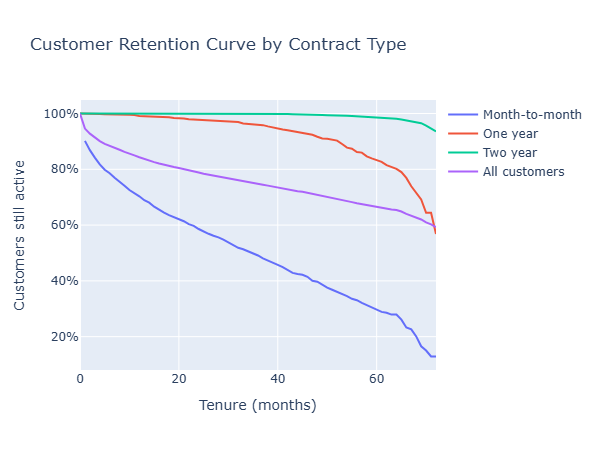

In [99]:
from IPython.display import Image, display
display(Image("images/retention_curve.png"))

In [ ]:
ret.loc[[12, 24, 36, 60, 72]].mul(100).round(1)

,Month-to-month,One year,Two year,All customers
tenure,,,,
12,70.3,99.1,100.0,84.3
24,58.6,97.8,100.0,78.9
36,49.1,95.9,99.9,74.9
60,29.7,83.2,98.6,66.4
72,12.9,56.8,93.6,59.3


In [100]:
ret.loc[[12, 24, 36, 60, 72]].mul(100).round(1)

,Month-to-month,One year,Two year,All customers
tenure,,,,
12,70.3,99.1,100.0,84.3
24,58.6,97.8,100.0,78.9
36,49.1,95.9,99.9,74.9
60,29.7,83.2,98.6,66.4
72,12.9,56.8,93.6,59.3


Retention falls fastest for month-to-month customers: 70.3% are still active after 12 months and 58.6% after 24, compared with 99.1% and 97.8% for one-year contracts and 100% for two-year contracts. By month 36 about half of month-to-month customers have left (49.1% retained), while two-year customers are still at 99.9%. The tails of the curves rest on fewer customers, so I read the first three years most confidently.

In [101]:
churn_summary("PaymentMethod")

,Customers,Churned,Churn_Rate_%
PaymentMethod,,,
Bank transfer (automatic),1544,258,16.7
Credit card (automatic),1522,232,15.2
Electronic check,2365,1071,45.3
Mailed check,1612,308,19.1


Electronic check customers churn at 45.3%, about three times the rate of customers paying by automatic bank transfer (16.7%) or credit card (15.2%). Mailed check sits at 19.1%. Electronic check is also the largest group (2,365 customers) and accounts for 1,071 of the 1,869 churners, about 57%.

In [102]:
churn_summary("PaperlessBilling")

,Customers,Churned,Churn_Rate_%
PaperlessBilling,,,
No,2872,469,16.3
Yes,4171,1400,33.6


Customers on paperless billing churn at 33.6% versus 16.3% for those who are not. I treat this as a signal to check, since it may overlap with electronic check payments and month-to-month contracts.

In [103]:
#MonthlyCharges
df["ChargeBand"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 70, 90, 120],
    labels=["Under $35", "$35-70", "$70-90", "Over $90"],
)
churn_summary("ChargeBand")

,Customers,Churned,Churn_Rate_%
ChargeBand,,,
Under $35,1735,189,10.9
$35-70,1725,413,23.9
$70-90,1844,697,37.8
Over $90,1739,570,32.8


Churn rises with price up to the $70-90 band: 10.9% under $35, 23.9% for $35-70 and 37.8% for $70-90. It eases slightly to 32.8% above $90. Customers paying $70 or more are the most likely to leave.

In [104]:
churn_summary("InternetService")

,Customers,Churned,Churn_Rate_%
InternetService,,,
DSL,2421,459,19.0
Fiber optic,3096,1297,41.9
No,1526,113,7.4


Fiber optic customers churn at 41.9% (3,096 customers), about twice the DSL rate (19.0%). Customers without internet churn least, at 7.4%.

In [105]:
churn_summary("TechSupport")

,Customers,Churned,Churn_Rate_%
TechSupport,,,
No,3473,1446,41.6
No internet service,1526,113,7.4
Yes,2044,310,15.2


In [106]:
churn_summary("OnlineSecurity")

,Customers,Churned,Churn_Rate_%
OnlineSecurity,,,
No,3498,1461,41.8
No internet service,1526,113,7.4
Yes,2019,295,14.6


Customers without tech support churn at 41.6% versus 15.2% with it. Online security shows the same pattern (41.8% without, 14.6% with). Customers with no internet service (7.4%) are shown separately because the add-ons don't apply to them.

In [107]:
#the high-risk segment
internet = df[df["InternetService"] != "No"]
(internet.pivot_table(index="InternetService", columns="TechSupport",
                      values="ChurnFlag", aggfunc="mean") * 100).round(1)

TechSupport,No,Yes
InternetService,,
DSL,27.8,9.7
Fiber optic,49.4,22.6


Tech support goes with lower churn in both groups: for fiber optic it falls from 49.4% to 22.6%, and for DSL from 27.8% to 9.7%. Fiber optic customers without support are the highest-risk group.

In [108]:
internet.pivot_table(index="InternetService", columns="TechSupport",
                     values="ChurnFlag", aggfunc="count")

TechSupport,No,Yes
InternetService,,
DSL,1243,1178
Fiber optic,2230,866


In [109]:
#Measure the high-risk segment
risk = (df["InternetService"] == "Fiber optic") & (df["TechSupport"] == "No")

print("Customers in segment:", risk.sum(), f"({risk.mean():.1%} of base)")
print("Churn rate in segment:", f"{df[risk]['ChurnFlag'].mean():.1%}")
print("Churn rate elsewhere:", f"{df[~risk]['ChurnFlag'].mean():.1%}")
print("Share of all churners:", f"{df[risk]['ChurnFlag'].sum() / df['ChurnFlag'].sum():.1%}")

Customers in segment: 2230 (31.7% of base)
Churn rate in segment: 49.4%
Churn rate elsewhere: 16.0%
Share of all churners: 58.9%


Fiber optic customers without tech support are 31.7% of the base (2,230 customers) and churn at 49.4%, compared with 16.0% for all other customers. They account for 58.9% of all churners.

In [110]:
df[risk].groupby("Contract")["ChurnFlag"].agg(Customers="count", Churn_Rate="mean").round(3)

,Customers,Churn_Rate
Contract,,
Month-to-month,1796,0.575
One year,313,0.185
Two year,121,0.083


About 80% of the Fiber optic / no tech support segment (1,796 of 2,230 customers) is on a month-to-month contract, where its churn rate reaches 57.5%. The segment churns more than the average customer on the same contract at every level (57.5% vs 42.7% for month-to-month, 18.5% vs 11.3% for one-year and 8.3% vs 2.8% for two-year), so the risk is not explained by contract type alone. The two-year group is small (121 customers), so I read it as indicative.

In [111]:
(df.pivot_table(index="PaymentMethod", columns="Contract",
                values="ChurnFlag", aggfunc="mean") * 100).round(1)

Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),34.1,9.7,3.4
Credit card (automatic),32.8,10.3,2.2
Electronic check,53.7,18.4,7.7
Mailed check,31.6,6.8,0.8


Electronic check customers churn more than other customers on every contract type: 53.7% on month-to-month (against 31.6-34.1% for other payment methods), 18.4% on one-year (6.8-10.3%) and 7.7% on two-year (0.8-3.4%). The electronic check effect is therefore not explained by contract type alone, although it may still reflect other differences between these customers. Counts are small for some two-year cells, so I read those rates as indicative.

In [112]:
core = risk & (df["Contract"] == "Month-to-month")
print(core.sum(), f"{core.mean():.1%} of base,",
      f"churn {df[core]['ChurnFlag'].mean():.1%},",
      f"{df[core]['ChurnFlag'].sum() / df['ChurnFlag'].sum():.1%} of all churners")

1796 25.5% of base, churn 57.5%, 55.3% of all churners


In [113]:
#Heatmap 1: tenure cohort by contract type
heat = (df.pivot_table(index="TenureCohort", columns="Contract",
                       values="ChurnFlag", aggfunc="mean", observed=True) * 100).round(1)

fig1 = px.imshow(
    heat, text_auto=True, aspect="auto",
    color_continuous_scale="Reds",
    labels=dict(color="Churn rate %"),
    title="Churn Rate (%) by Tenure Cohort and Contract Type",
)
fig1.update_layout(xaxis_title="Contract", yaxis_title="Tenure cohort (months)")
fig1.show()

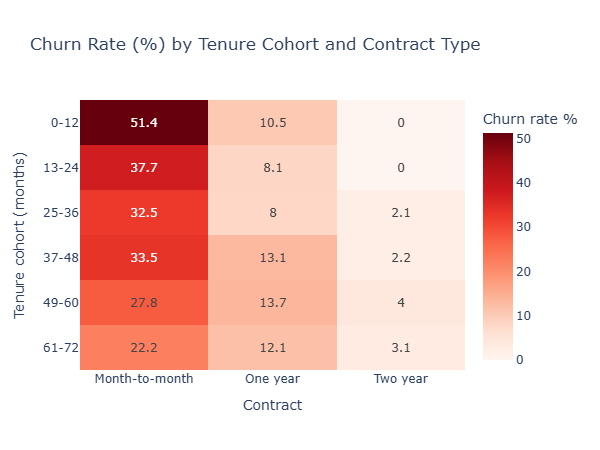

In [114]:
from IPython.display import Image, display
display(Image("images/heatmap_tenure_contract.png"))

Churn is concentrated in month-to-month customers, and it falls with tenure within that column, from 51.4% in the first year to 22.2% after five years. One-year contracts stay between 8% and 14% and two-year contracts below 5%, with 0% churn in the first two years. The highest-risk group is new month-to-month customers.

In [115]:
#Heatmap 2: churn by service tier
seg = df[df["InternetService"] != "No"].copy()
seg["Service tier"] = seg["InternetService"] + " | Tech support: " + seg["TechSupport"]

heat2 = (seg.pivot_table(index="Service tier", columns="Contract",
                         values="ChurnFlag", aggfunc="mean") * 100).round(1)

fig2 = px.imshow(
    heat2, text_auto=True, aspect="auto",
    color_continuous_scale="Reds",
    labels=dict(color="Churn rate %"),
    title="Churn Rate (%) by Service Tier and Contract Type",
)
fig2.update_layout(xaxis_title="Contract", yaxis_title="")
fig2.show()

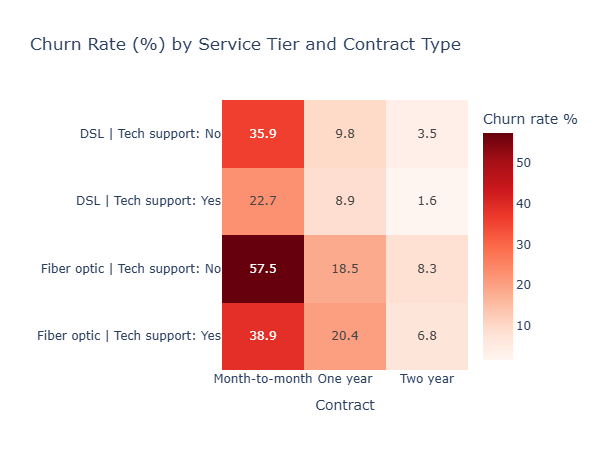

In [116]:
from IPython.display import Image, display
display(Image("images/heatmap_service_tier.png"))

Fiber optic customers without tech support on month-to-month contracts number 1,796 (25.5% of customers), churn at 57.5%, and account for 55.3% of all churners.